In [3]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

In [10]:
x = sp.symbols('x')
r, N, x_c = sp.symbols('r N x_c', real=True)

S = 1 / (1 + sp.exp(x_c - x))

F = ((1 - S) + S * (x / (N + x))) * r * x

fixed_eq = sp.Eq(x, F)
fixed_eq

Eq(x, r*x*(x/((N + x)*(exp(-x + x_c) + 1)) + 1 - 1/(exp(-x + x_c) + 1)))

In [5]:
solutions = sp.solve(fixed_eq, x)
solutions

NotImplementedError: multiple generators [x, exp(x)]
No algorithms are implemented to solve equation -r*x*(x/((N + x)*(exp(-x + x_c) + 1)) + 1 - 1/(exp(-x + x_c) + 1)) + x

In [11]:
dF = sp.diff(F, x)
print(dF.simplify())
dF.simpify()

r*(x*(x*(N + x) - x*(exp(x - x_c) + 1) - (N + x)**2 + (N + x)*(exp(x - x_c) + 1))*exp(3*x - 3*x_c) + (N + x)*(exp(x - x_c) + 1)*(x*exp(x - x_c) + (N + x)*(exp(x - x_c) + 1) - (N + x)*exp(x - x_c))*exp(2*x - 2*x_c))*exp(-2*x + 2*x_c)/((N + x)**2*(exp(x - x_c) + 1)**2)


AttributeError: 'Add' object has no attribute 'simpify'

In [13]:
dFx_stac0 = dF.subs(x, 0)
dFx_stac0

r*(1 - 1/(exp(x_c) + 1))

In [14]:
dFx_stac0.simplify()

r*exp(x_c)/(exp(x_c) + 1)

In [46]:
def F(x, r_a, r_s, N, xc):
    return x*(r_a * (1 - 1/(1 + np.exp(xc - x)))
                + (x * r_s)/((1 + np.exp(xc - x))*(N + x)))

def dF_dx(x, r_a, r_s, N, xc, h=1e-6):
    return (F(x+h, r_a, r_s, N, xc) - F(x-h, r_a, r_s, N, xc)) / (2*h)

def plot_stability(param_sets, x_max_map, r_max_map, ncols, x_len, y_len, r_s):
    nrows = int(np.ceil(len(param_sets) / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(x_len, y_len))
    axes = axes.flatten()
    
    for ax, (N, xc) in zip(axes, param_sets):
        x_max = xc + 25 
        r_max = 20
        x = np.linspace(0, x_max, 500)
        r = np.linspace(0, r_max, 500)
        R, X = np.meshgrid(r, x)
    
        G = X - F(X, R, r_s, N, xc)
        dF = dF_dx(X, R, r_s, N, xc)
        
        stable = (dF > -1) & (dF < 1)
    
        # ax.contourf(
        #     R, X, stable,
        #     levels=[0.5, 1],
        #     colors=['#ccffe5'],
        #     alpha=0.7
        # )
        # 
        # ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
        # ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
        # ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')
        
        ax.contourf(
            R, X, stable,
            levels=[0.5, 1],
            colors=['#ccffe5'],
            alpha=0.8
        )

        # ===== КРИВЫЕ =====
        c_stationary = ax.contour(
            R, X, G,
            levels=[0],
            colors='black',
            linewidths=2
        )

        c_minus = ax.contour(
            R, X, dF,
            levels=[-1],
            colors='blue',
            linestyles='dashed'
        )

        c_plus = ax.contour(
            R, X, dF,
            levels=[1],
            colors='red',
            linestyles='dashed'
        )

        # ===== ПОДПИСИ НА ЛИНИЯХ =====
        mask = np.abs(G) < 0.01 * x_max
        i, j = np.argwhere(mask)[len(np.argwhere(mask)) // 2]
        
        ax.text(
            R[i, j], X[i, j], 'x*',
            fontsize=8,
            ha='center',
            va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=0.3)
        )
        ax.clabel(c_minus, fmt={-1: 'F`=-1'}, fontsize=8)
        ax.clabel(c_plus, fmt={1: 'F`=1'}, fontsize=8)

        # ===== ПОДПИСЬ ВНУТРИ ЗЕЛЁНОЙ ОБЛАСТИ =====
        # выбираем точку, где stable == True
        idx = np.argwhere(stable)
        if idx.size > 0:
            i, j = idx[len(idx) // 2]
            ax.text(
                R[i, j], X[i, j], '|F`|<1',
                fontsize=8,
                color='black',
                ha='center',
                va='center'
            )
    
        ax.set_title(f"r_s = {r_s}, xc = {xc}, N = {N}")
        ax.set_xlabel("r_a")
        ax.set_ylabel("x")
        ax.grid(True, linestyle=":", alpha=0.6)
    for i in range(len(param_sets), len(axes)):
        axes[i].axis("off")
    
    # plt.suptitle(
    #     "Неявные стационарные кривые G(x,r)=0 и область |F'(x)| < 1\n"
    #     "Сравнение для различных N и xc",
    #     fontsize=16
    # )
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

In [41]:
xc_values = [0.5, 2, 5, 15, 40]
N_values  = [0.5, 1, 10, 25, 50, 100, 250, 500]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]
x_max_map = {}
r_max_map = {}
ncols = 5

# plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 25, 0.8)

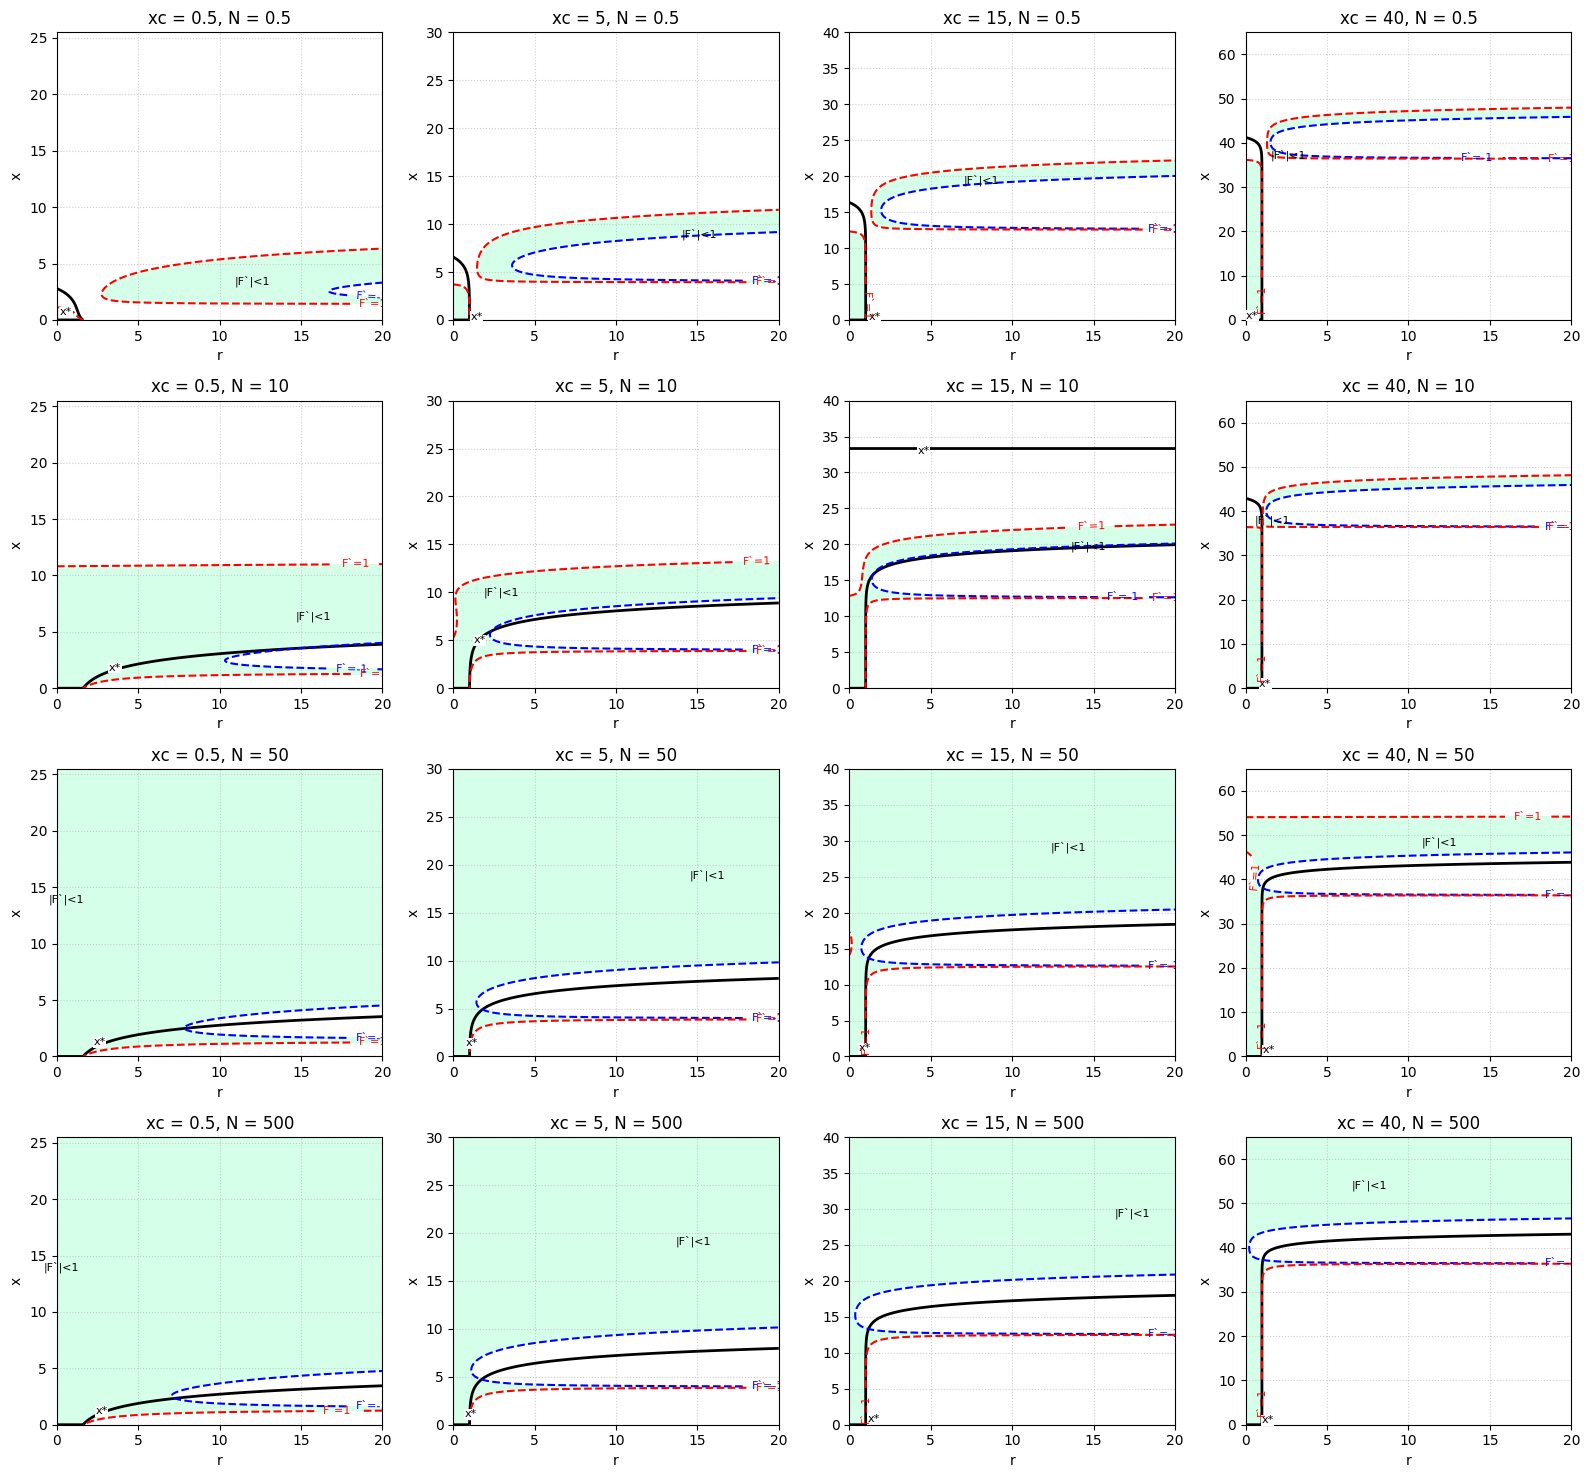

In [34]:
xc_values = [0.5, 5, 15, 40]
N_values  = [0.5, 10, 50, 500]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]
x_max_map = {}
r_max_map = {}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 16, 1.3)

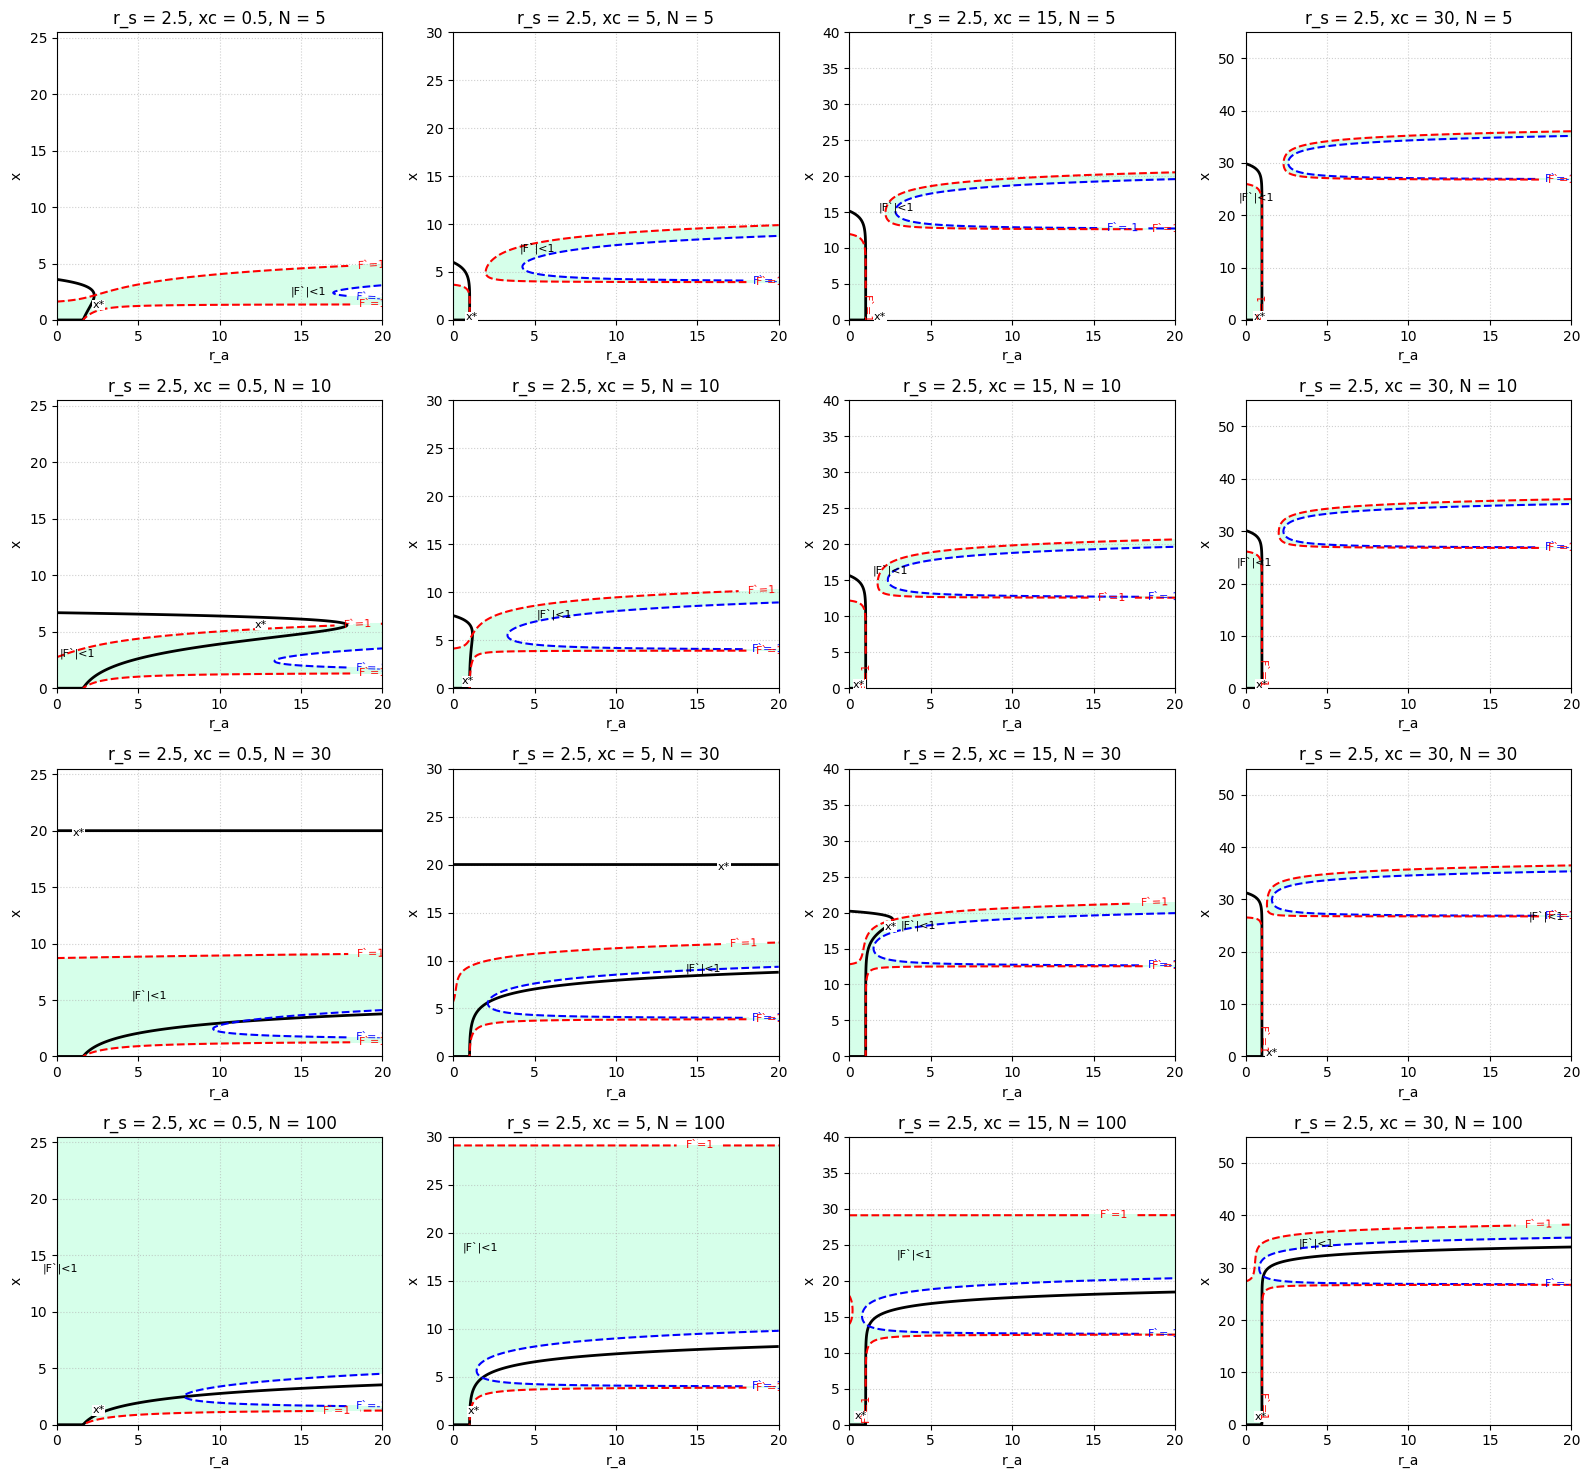

In [47]:
xc_values = [0.5, 5, 15, 30]
N_values  = [5, 10, 30, 100]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]
x_max_map = {}
r_max_map = {}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 16, 2.5)

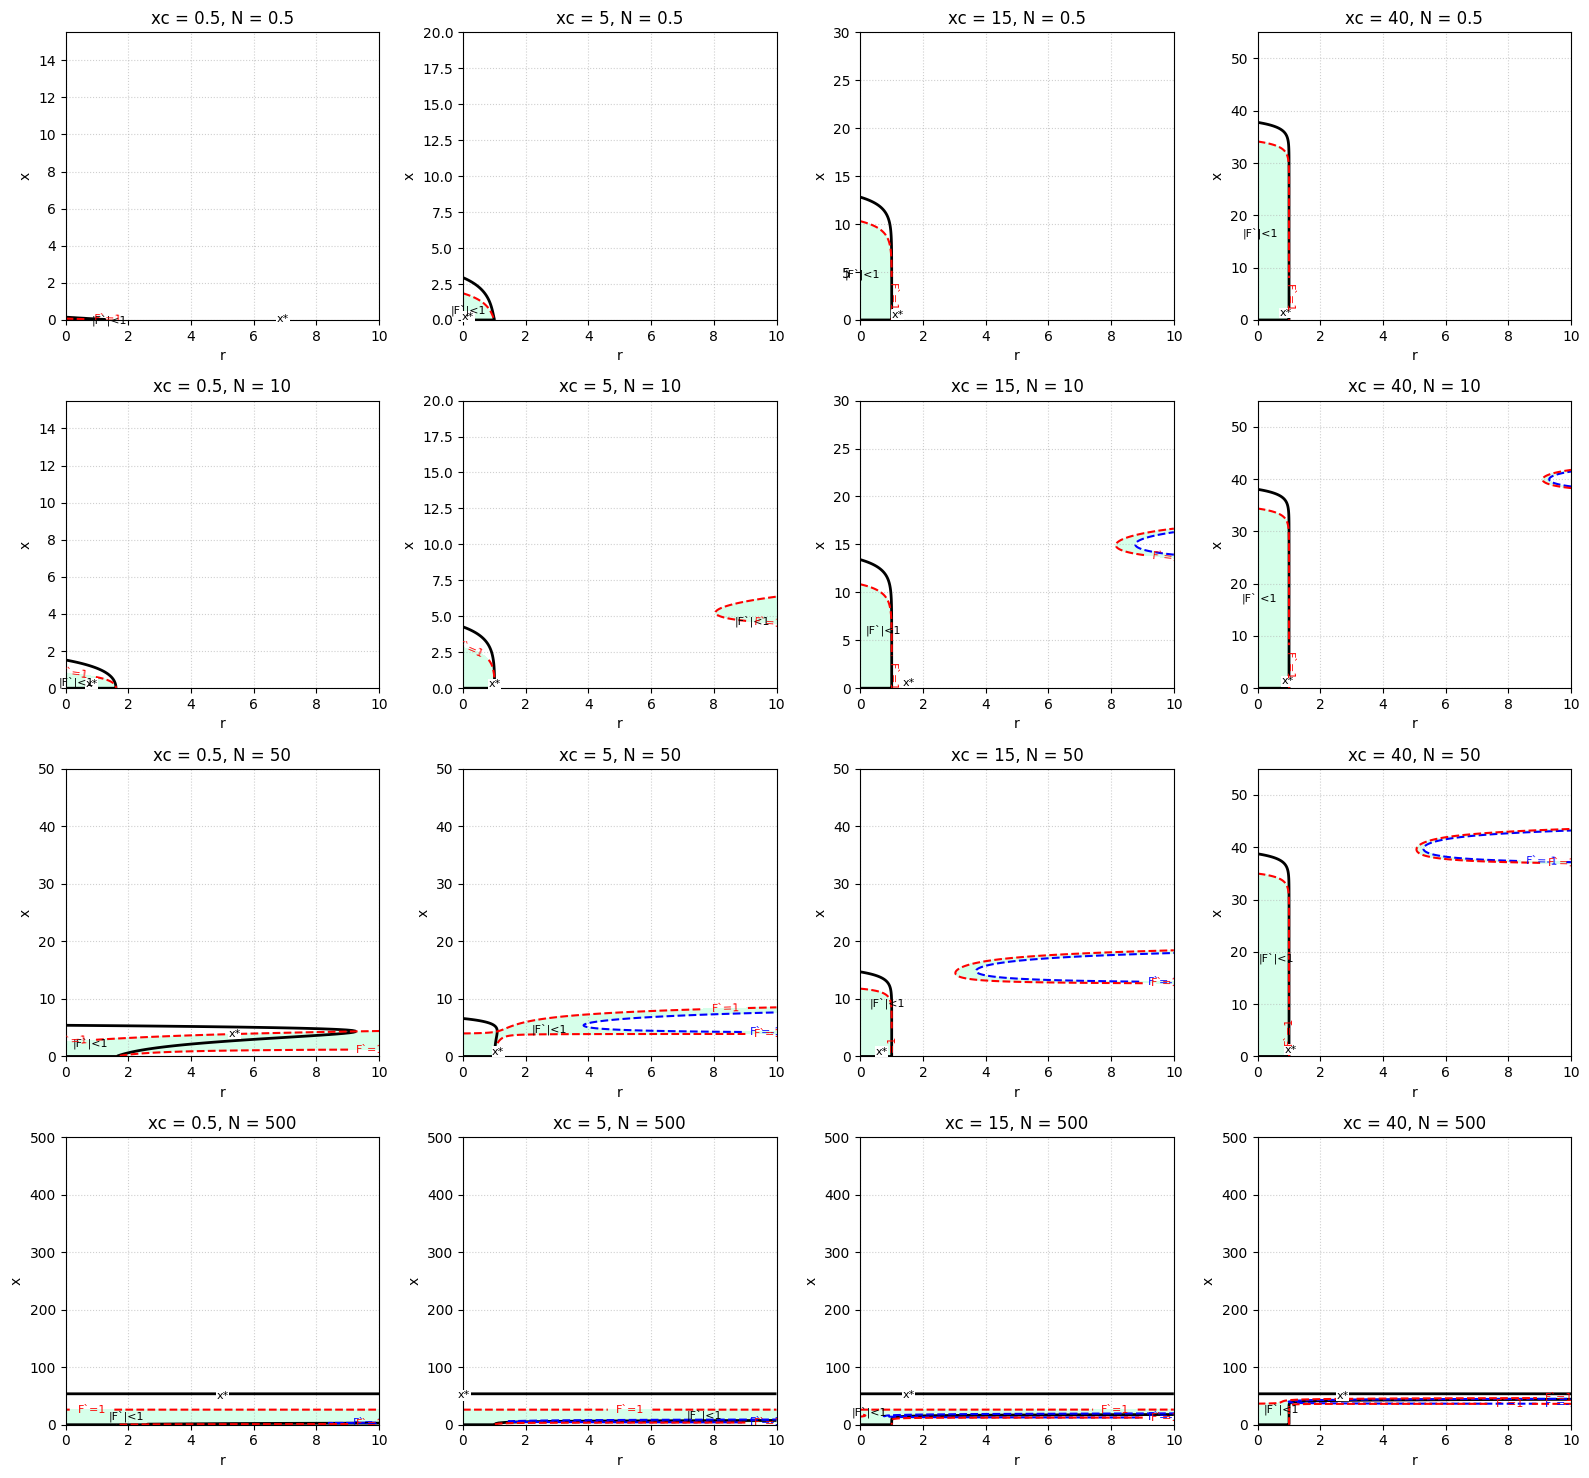

In [30]:
xc_values = [0.5, 5, 15, 40]
N_values  = [0.5, 10, 50, 500]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]
x_max_map = {}
r_max_map = {}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 16, 10.3)